In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_path = "../data/traffic/traffic.jpg"

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError("Traffic image not found.")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("Original shape:", image.shape)
print("Original min:", image.min())
print("Original max:", image.max())

Original shape: (475, 421, 3)
Original min: 0
Original max: 255


In [2]:
def letterbox(image, target_size=(640, 640)):
    h, w = image.shape[:2]
    target_w, target_h = target_size

    scale = min(target_w / w, target_h / h)

    new_w = int(w * scale)
    new_h = int(h * scale)

    resized = cv2.resize(
        image,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )

    canvas = np.zeros(
        (target_h, target_w, 3),
        dtype=np.uint8
    )

    x_offset = (target_w - new_w) // 2
    y_offset = (target_h - new_h) // 2

    canvas[
        y_offset:y_offset + new_h,
        x_offset:x_offset + new_w
    ] = resized

    return canvas

In [3]:
processed = letterbox(image_rgb)

normalized = processed.astype(np.float32) / 255.0

print("Processed shape:", normalized.shape)
print("Processed min:", normalized.min())
print("Processed max:", normalized.max())

Processed shape: (640, 640, 3)
Processed min: 0.0
Processed max: 1.0


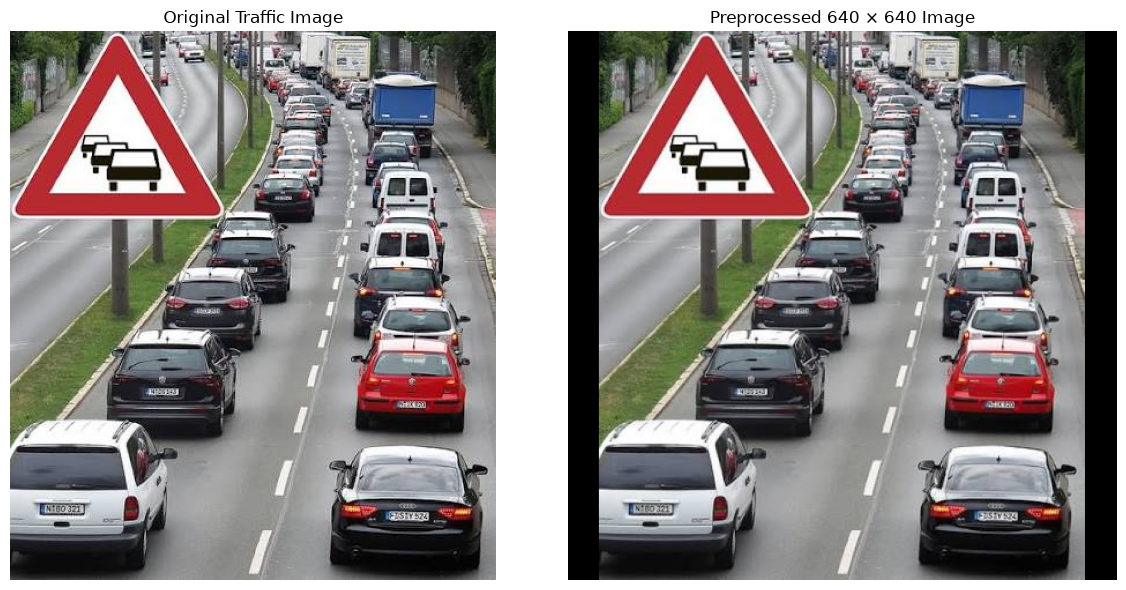

In [4]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Traffic Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(normalized)
plt.title("Preprocessed 640 × 640 Image")
plt.axis("off")

plt.tight_layout()
plt.show()